# Лекция 6. численное дифференцирование функций

## 1. 🎯 Постановка задачи

Численное дифференцирование — это нахождение приближённых значений производных функции $y=f(x)$ в заданных точках $x$.

Обычно функция задана не аналитически, а таблицей значений в узлах:

$$
x_i = x_0 + ih, \qquad y_i = f(x_i), \qquad i=0,1,\dots,n,
$$

где $h>0$ - шаг сетки.

Требуется построить формулы вида

$$
f^{(k)}(x_i) \approx \sum_j c_j f(x_j),
$$

которые позволяют вычислять производные через значения функции в близких узлах.

## 2. 💡 Идея вывода формул

Основной источник формул численного дифференцирования — **полиномиальная интерполяция**.

Если известны значения $y_i=f(x_i)$, можно построить интерполяционный многочлен $P_n(x)$, например многочлен Ньютона, а затем приближённо положить

$$
f^{(k)}(x) \approx P_n^{(k)}(x).
$$

Остаточные члены получаются дифференцированием остаточного члена интерполяционной формулы или с помощью формулы Тейлора.

> 🧠 **Связь с Разделом 1:** таблицы конечных разностей — из лекции 2, а идея «дифференцируем интерполянт» — прямое продолжение многочленов Лагранжа и Ньютона.

### 📐 2.1 Первый многочлен Ньютона и общая формула

Распишем идею выше — дифференцируем интерполянт — для равномерной сетки $x_j=x_0+jh$. С переменной $q=(x-x_0)/h$ первый многочлен Ньютона:

$$
f(x)\approx P_n(x_0+qh)=y_0+q\Delta y_0+\frac{q(q-1)}{2!}\Delta^2y_0+\frac{q(q-1)(q-2)}{3!}\Delta^3y_0+\dots 
$$

Так как $dq/dx=1/h$:

$$
f'(x)\approx\frac{1}{h}\left[\Delta y_0+\frac{2q-1}{2}\Delta^2y_0+\frac{3q^2-6q+2}{6}\Delta^3y_0+\dots\right] 
$$

При $n=1,2,3$ общая формула даёт частные случаи. Для линейной интерполяции:

$$f'(x)\approx\frac{\Delta y_0}{h}$$

для квадратичной добавляется член с $\Delta^2 y_0$:

$$f'(x)\approx\frac{1}{h}\left(\Delta y_0+\frac{2q-1}{2}\Delta^2 y_0\right)$$

для кубической — ещё член с $\Delta^3 y_0$. А при $q=0,1,2,3$ получаются узловые формулы ниже: производная выражается напрямую через значения $y_0,y_1,y_2,y_3$. 

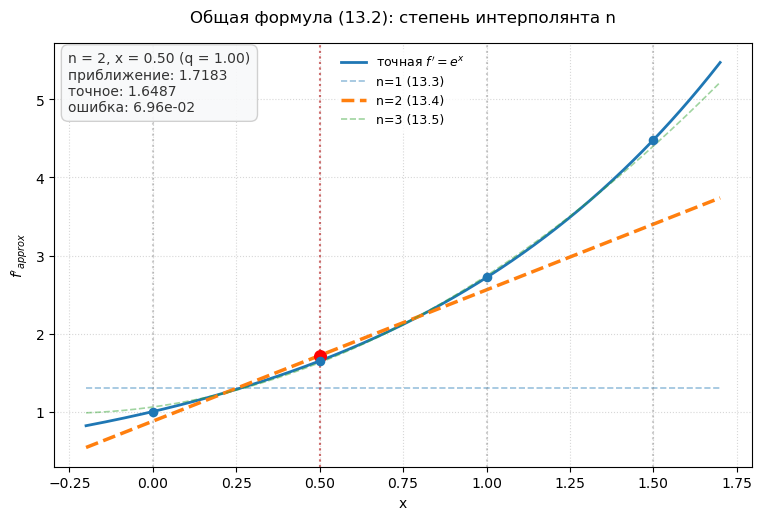

interactive(children=(IntSlider(value=2, description='n:', max=3, min=1), FloatSlider(value=0.5, description='…

In [11]:
%matplotlib inline
from utils import run_newton_orders_interactive

run_newton_orders_interactive()

## 3. 👣 Простейшие аппроксимации первой производной

Запишем формулу Тейлора в окрестности точки $x_i$:

$$
f(x)=f(x_i)+f'(x_i)(x-x_i)+\frac{f''(\xi)}{2}(x-x_i)^2.
$$

Отсюда

$$
f'(x_i)=\frac{f(x)-f(x_i)}{x-x_i}-\frac{f''(\xi)}{2}(x-x_i). 
$$

### ⬅️ Левая разностная производная

При $x=x_{i-1}$:

$$
f'(x_i)=\frac{y_i-y_{i-1}}{h}+\frac{f''(\xi_{i-1})}{2}h. 
$$

Приближённо:

$$
f'(x_i)\approx \frac{y_i-y_{i-1}}{h}. 
$$

### ➡️ Правая разностная производная

При $x=x_{i+1}$:

$$
f'(x_i)=\frac{y_{i+1}-y_i}{h}-\frac{f''(\xi_{i+1})}{2}h. 
$$

Приближённо:

$$
f'(x_i)\approx \frac{y_{i+1}-y_i}{h}. 
$$

Обе формулы имеют **первый порядок точности**, то есть ошибка $O(h)$. 🐢

## 4. ⚖️ Симметричная аппроксимация первой производной

Разложим функцию в точках $x_{i+1}$ и $x_{i-1}$:

$$
f(x_{i+1})=f(x_i)+f'(x_i)h+\frac12 f''(x_i)h^2+\frac16 f'''(\xi_{i+1})h^3,
$$

$$
f(x_{i-1})=f(x_i)-f'(x_i)h+\frac12 f''(x_i)h^2-\frac16 f'''(\xi_{i-1})h^3.
$$

Вычитая второе равенство из первого, получаем центральную разностную формулу:

$$
f'(x_i)=\frac{y_{i+1}-y_{i-1}}{2h}-\frac{h^2}{6}f'''(\xi_i). 
$$

Приближённая формула:

$$
f'(x_i)\approx \frac{y_{i+1}-y_{i-1}}{2h}.
$$

Это **второй порядок точности**: ошибка $O(h^2)$. 🐇

#### 🔬 Пример: проверяем порядки делением шага пополам

Односторонние формулы — $O(h)$, центральная — $O(h^2)$ (см. остаточные члены выше). Как в лекции 1, делим $h$ пополам и смотрим, во сколько раз падает ошибка: в 2 раза — первый порядок, в 4 — второй.

In [12]:
import numpy as np
f = lambda x: np.sin(x)
exact = np.cos(1.0)
print(f"точная f'(1)=cos(1)={exact:.10f}\n")
print(f"{'h':>8} | {'левая':>10} {'err':>9} | {'правая':>10} {'err':>9} | {'центр.':>10} {'err':>9}")
for h in [0.2, 0.1, 0.05, 0.025]:
    l = (f(1.0)-f(1.0-h))/h; r=(f(1.0+h)-f(1.0))/h; c=(f(1.0+h)-f(1.0-h))/(2*h)
    print(f"{h:8.3f} | {l:10.7f} {abs(l-exact):9.2e} | {r:10.7f} {abs(r-exact):9.2e} | {c:10.7f} {abs(c-exact):9.2e}")
print("\nОдносторонние: /2 при h/2 (1-й порядок). Центральная: /4 (2-й порядок).")



точная f'(1)=cos(1)=0.5403023059

       h |      левая       err |     правая       err |     центр.       err
   0.200 |  0.6205745  8.03e-02 |  0.4528405  8.75e-02 |  0.5367075  3.59e-03
   0.100 |  0.5814408  4.11e-02 |  0.4973638  4.29e-02 |  0.5394023  9.00e-04
   0.050 |  0.5611096  2.08e-02 |  0.5190448  2.13e-02 |  0.5400772  2.25e-04
   0.025 |  0.5507639  1.05e-02 |  0.5297282  1.06e-02 |  0.5402460  5.63e-05

Односторонние: /2 при h/2 (1-й порядок). Центральная: /4 (2-й порядок).


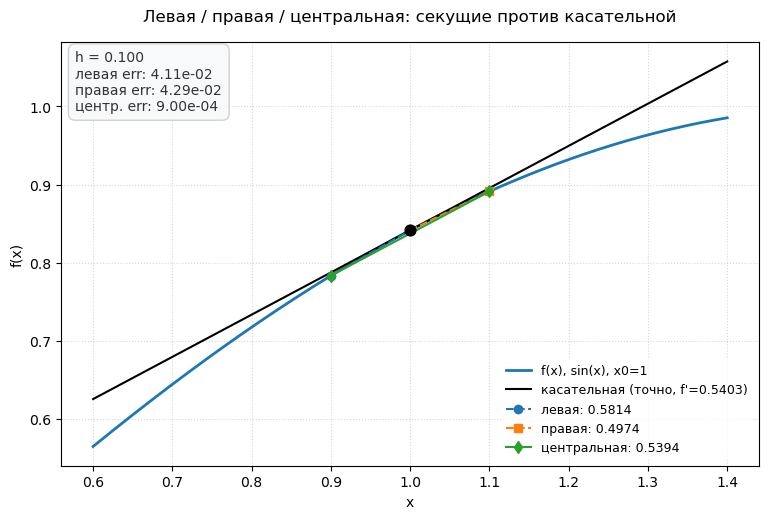

interactive(children=(FloatSlider(value=0.1, description='шаг h:', max=0.4, min=0.02, step=0.01), Dropdown(des…

In [13]:
%matplotlib inline
from utils import run_fd_comparison_interactive

run_fd_comparison_interactive()

## 5. 📍 Несимметричные формулы второго порядка

Для крайних узлов можно использовать несимметричные аппроксимации второго порядка точности:

$$
f'(x_{i-1})=\frac{-3y_{i-1}+4y_i-y_{i+1}}{2h}+\frac{h^2}{3}f'''(\xi_{i-1}), 
$$

$$
f'(x_{i+1})=\frac{y_{i-1}-4y_i+3y_{i+1}}{2h}+\frac{h^2}{3}f'''(\xi_{i+1}).
$$

Остаточный член здесь в два раза больше по коэффициенту, чем у симметричной формулы. ✌️

#### ⚔️ Пример: краевая формула вдвое грубее центральной

Возьмём $f(x)=e^x$ в точке $x=0$ при $h=0.2$. Центральная и краевая слева формулы — обе второго порядка, но остаток краевой $h^2f'''/3$ вдвое больше остатка центральной $-h^2f'''/6$ . Проверяем:

In [14]:
import numpy as np

f = lambda x: np.exp(x)
x0, h = 0.0, 0.2
exact = np.exp(x0)
central = (f(x0 + h) - f(x0 - h)) / (2 * h)
edge = (-3 * f(x0) + 4 * f(x0 + h) - f(x0 + 2 * h)) / (2 * h)
print(f"точная f'(0) = {exact:.8f}")
print(f"центральная:        {central:.8f}  err={abs(central - exact):.2e}")
print(f"краевая слева:      {edge:.8f}  err={abs(edge - exact):.2e}")
print(f"отношение ошибок: {abs(edge - exact) / abs(central - exact):.2f} (теория предсказывает ~2)" )

точная f'(0) = 1.00000000
центральная:        1.00668001  err=6.68e-03
краевая слева:      0.98446584  err=1.55e-02
отношение ошибок: 2.33 (теория предсказывает ~2)


## 6. 📜 Общие формулы остаточных членов

Для приближённых формул

$$
f^{(k)}(x)\approx L_n^{(k)}(x)
$$

остаточные члены можно записывать в общем виде. Например:

$$
f''(x)-L_n''(x)=
\frac{f^{(n+1)}(\xi)}{(n+1)!}\Pi_{n+1}''(x)
+
2\frac{f^{(n+2)}(\xi_1)}{(n+2)!}\Pi_{n+1}'(x)
+
\frac{f^{(n+3)}(\xi_2)}{(n+3)!}\Pi_{n+1}(x). 
$$

В общем случае:

$$
f^{(k)}(x)-L_n^{(k)}(x)
=
\sum_{j=0}^{k}
\frac{k!}{(k-j)!(n+j+1)!}
f^{(n+j+1)}(\xi_j)\Pi_{n+1}^{(k-j)}(x). 
$$

Эти формулы полезны для качественного сравнения точности различных аппроксимаций. 🔍

## 7. 🛠️ Аппроксимация второй производной

Будем искать формулу вида

$$
f''(x_i)\approx c_1 f(x_i-h)+c_2 f(x_i)+c_3 f(x_i+h).
$$

Подставим вместо $f(x)$ последовательно функции $1$, $x$, $x^2$. Для второй производной получаем систему:

$$
\begin{cases}
c_1+c_2+c_3=0,\\
c_1(x_i-h)+c_2x_i+c_3(x_i+h)=0,\\
c_1(x_i-h)^2+c_2x_i^2+c_3(x_i+h)^2=2.
\end{cases}
$$

Отсюда

$$
c_1=c_3=\frac{1}{h^2},\qquad c_2=-\frac{2}{h^2}.
$$

Следовательно,

$$
f''(x_i)\approx \frac{y_{i-1}-2y_i+y_{i+1}}{h^2}.
$$

Формула точна для многочленов второй степени, а в точке $x_i$ — и для многочленов третьей степени.

> 🧠 **Куда это пойдёт:** формула центральной разности выше и формула второй производной из этого параграфа — строительные блоки конечно-разностных методов, с которыми встретимся при решении краевых задач и уравнений в частных производных.

In [7]:
# Формула второй производной точна на многочленах: в узле симметрии — даже для 3-й степени
import numpy as np

g = lambda x: np.sin(x)
g2 = lambda x: -np.sin(x)
xi = 1.0
for h in [0.4, 0.2, 0.1, 0.05]:
    a = (g(xi - h) - 2 * g(xi) + g(xi + h)) / h ** 2
    print(f"h={h:4.2f} approx={a: .7f} exact={g2(xi): .7f} err={abs(a - g2(xi)):.1e}")
print()
for deg in [2, 3, 4]:
    pp = lambda x, d=deg: x ** d
    exact = deg * (deg - 1) * xi ** (deg - 2)
    a = (pp(xi - 0.3) - 2 * pp(xi) + pp(xi + 0.3)) / 0.3 ** 2
    flag = "ТОЧНО" if abs(a - exact) < 1e-9 else "не точно (так и должно быть при deg=4)"
    print(f"  x^{deg}: approx={a:.5f} exact={exact:.5f} {flag}")


h=0.40 approx=-0.8303110 exact=-0.8414710 err=1.1e-02
h=0.20 approx=-0.8386698 exact=-0.8414710 err=2.8e-03
h=0.10 approx=-0.8407700 exact=-0.8414710 err=7.0e-04
h=0.05 approx=-0.8412957 exact=-0.8414710 err=1.8e-04

  x^2: approx=2.00000 exact=2.00000 ТОЧНО
  x^3: approx=6.00000 exact=6.00000 ТОЧНО
  x^4: approx=12.18000 exact=12.00000 не точно (так и должно быть при deg=4)


## 8. 🎚️ Влияние вычислительной погрешности. Оптимальный шаг

Пусть значения функции известны с погрешностью $\delta$:

$$
|\tilde f(x)-f(x)|\le \delta.
$$

Для правой разностной формулы

$$
f'(x_i)\approx \frac{y_{i+1}-y_i}{h}
$$

полная абсолютная погрешность оценивается как

$$
\left|f'(x_i)-\frac{y_{i+1}-y_i}{h}\right|
\le
\frac{2\delta}{h}+\frac{M_2}{2}h,
$$

где

$$
M_2=\max_{x\in[x_i,x_{i+1}]}|f''(x)|.
$$

Обозначим

$$
g(h)=\frac{2\delta}{h}+\frac{M_2}{2}h. 
$$

При $h\to 0$ первое слагаемое растёт, при больших $h$ растёт второе. Минимум достигается при

$$
h_{\text{opt}}=2\sqrt{\frac{\delta}{M_2}}.
$$

Если $\delta=2^{-m}$, $M_2=1$, то

$$
h_{\text{opt}}=2\cdot 2^{-m/2},
\qquad
g_{\min}=2\cdot 2^{-m/2}. 
$$

Вывод: для формул первого порядка точности шаг нельзя выбирать слишком малым. При машинных вычислениях часто берут $h=O(\sqrt{\delta})$.

#### 📉 Пример: $U$-кривая на числах


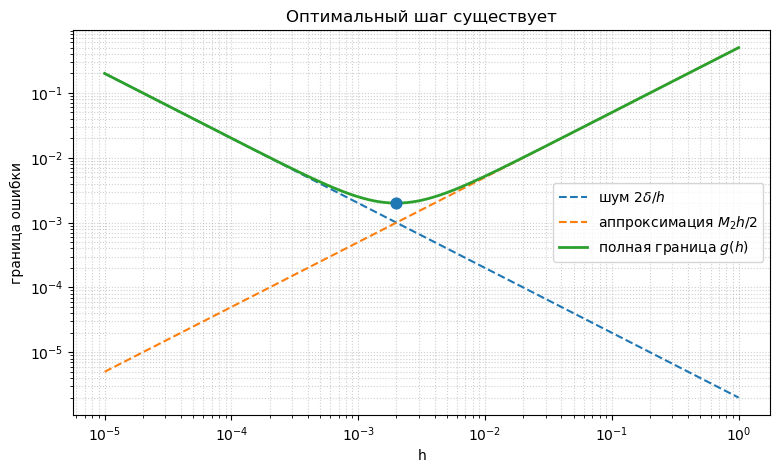

δ=1e-12: min err=2.1e-06 при h=9.2e-07 (теория 2√δ=2.0e-06)
δ=1e-07: min err=6.3e-04 при h=2.4e-04 (теория 2√δ=6.3e-04)


In [15]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
delta,M2=1e-6,1.0
h=np.logspace(-5,0,400); g=2*delta/h+M2*h/2
h_opt=2*np.sqrt(delta/M2); g_min=2*delta/h_opt+M2*h_opt/2
plt.figure(figsize=(9,5))
plt.loglog(h,2*delta/h,'--',label='шум $2\\delta/h$')
plt.loglog(h,M2*h/2,'--',label='аппроксимация $M_2h/2$')
plt.loglog(h,g,linewidth=2,label='полная граница $g(h)$')
plt.scatter([h_opt],[g_min],s=60,zorder=5)
plt.xlabel('h'); plt.ylabel('граница ошибки'); plt.grid(True,which='both',linestyle=':',alpha=0.6)
plt.title('Оптимальный шаг существует'); plt.legend(); plt.show()

# Та же U-кривая с искусственным шумом уровня delta
for delta in [1e-12,1e-7]:
    hs=np.logspace(-7,0,30)
    rng=np.random.default_rng(0); nz=rng.uniform(-delta,delta,2)
    errs=[abs(((np.exp(1+h)+nz[0])-(np.exp(1)+nz[1]))/h-np.exp(1)) for h in hs]
    i=int(np.argmin(errs))
    print(f"δ={delta:.0e}: min err={errs[i]:.1e} при h={hs[i]:.1e} (теория 2√δ={2*np.sqrt(delta):.1e})")